# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Ray Siraj
- **Email:** raydo.siraj@gmail.com
- **ID Dicoding:** DS009B6Y1514

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

## Menentukan Pertanyaan Bisnis

Dataset yang digunakan adalah **Bike Sharing Dataset**. Bayangkan kita adalah tim analitik operasional layanan bike sharing yang perlu menentukan **kapan** armada harus disiapkan, **kondisi apa** yang menekan permintaan, dan **ke mana** upaya pertumbuhan diarahkan.

- **Pertanyaan 1:** Pada jam berapa saja puncak rata-rata penyewaan sepeda per jam terjadi pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011-2012, dan berapa persen penyewaan hari kerja yang terjadi pada jam sibuk (06.00-09.59 dan 16.00-19.59), sehingga tim operasional dapat menjadwalkan redistribusi sepeda dan perawatan di luar jam puncak?
- **Pertanyaan 2:** Berapa persen penurunan rata-rata jumlah penyewaan harian pada cuaca berkabut/berawan dan hujan/salju ringan dibandingkan cuaca cerah, dan pada musim apa dampaknya paling besar sepanjang 2011-2012, sehingga tim dapat menyiapkan strategi mitigasi (promo, jumlah armada, perawatan) pada kondisi cuaca tertentu?
- **Pertanyaan 3:** Berapa pertumbuhan total penyewaan (year-over-year) tahun 2012 dibandingkan 2011, baik secara keseluruhan maupun per bulan, dan segmen mana (registered atau casual) yang tumbuh lebih cepat, sehingga alokasi anggaran pemasaran dan penambahan armada dapat diarahkan dengan tepat?

**Pengecekan SMART:**

| Pertanyaan | Specific | Measurable | Action-Oriented | Relevant | Time-bound |
|---|---|---|---|---|---|
| 1 | Pola jam hari kerja vs akhir pekan | Rata-rata penyewaan/jam dan % jam sibuk | Jadwal redistribusi & perawatan | Ketersediaan sepeda saat permintaan tinggi | 2011-2012 |
| 2 | Cuaca (weathersit) dan musim | % selisih rata-rata penyewaan harian vs cuaca cerah | Strategi mitigasi cuaca & promo | Permintaan menurun saat cuaca buruk | 2011-2012 |
| 3 | Total sewa 2012 vs 2011, registered vs casual | % pertumbuhan YoY | Prioritas pemasaran & armada | Pertumbuhan bisnis | 2011 vs 2012 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Tema visualisasi yang konsisten di seluruh notebook
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

BLUE, ORANGE, GREY, DARK = "#2F6DB5", "#E8833A", "#9AA5B1", "#1B3A5C"

## Data Wrangling

### Gathering Data

#### Load day_df

In [2]:
day_df = pd.read_csv("data/day.csv")
print("Ukuran day_df:", day_df.shape)
day_df.head()

Ukuran day_df: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load hour_df

In [3]:
hour_df = pd.read_csv("data/hour.csv")
print("Ukuran hour_df:", hour_df.shape)
hour_df.head()

Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris (1 Januari 2011 - 31 Desember 2012), satu baris per hari, dengan 16 kolom.
- `hour_df` berisi 17.379 baris dengan kolom tambahan `hr` (jam 0-23). Jika data lengkap, jumlah barisnya seharusnya 731 x 24 = 17.544, sehingga perlu dicek lebih lanjut pada tahap *assessing*.
- Kolom `temp`, `atemp`, `hum`, `windspeed` masih dalam bentuk ternormalisasi, dan kolom kategorikal (`season`, `weathersit`, `weekday`, dll.) masih berupa kode angka.

### Assessing Data

#### Identifying tipe data, missing value, dan data duplikat

In [4]:
day_df.info()
print("-" * 60)
hour_df.info()
print("-" * 60)
print("Missing value :", day_df.isna().sum().sum(), "(day_df) |", hour_df.isna().sum().sum(), "(hour_df)")
print("Data duplikat :", day_df.duplicated().sum(), "(day_df) |", hour_df.duplicated().sum(), "(hour_df)")

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 17379 en

**Steps to Take:**
- Kolom `dteday` bertipe teks (*object/str*), bukan tanggal. Perlu diubah ke `datetime` agar dapat dipakai untuk analisis waktu.
- Tidak ada *missing value* eksplisit dan tidak ada baris duplikat, sehingga tidak perlu penghapusan duplikat.

#### Identifying invalid value (kelembapan bernilai 0)

In [5]:
print("Jumlah hari dengan hum = 0 :", (day_df["hum"] == 0).sum())
print("Jumlah jam  dengan hum = 0 :", (hour_df["hum"] == 0).sum())
print("Tanggal terkait di hour_df :", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())
day_df.loc[day_df["hum"] == 0, ["dteday", "season", "weathersit", "hum", "cnt"]]

Jumlah hari dengan hum = 0 : 1
Jumlah jam  dengan hum = 0 : 22
Tanggal terkait di hour_df : <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


,dteday,season,weathersit,hum,cnt
68,2011-03-10,1,3,0.0,623


**Steps to Take:**
- Kelembapan udara 0% hampir mustahil terjadi, apalagi pada hari dengan cuaca hujan/salju ringan (`weathersit = 3`). Nilai ini **invalid** dan kemungkinan besar berasal dari kegagalan pencatatan sensor pada **10 Maret 2011** (seluruh 22 jam yang tercatat di tanggal itu bernilai 0).
- Nilai tersebut akan diganti dengan **median kelembapan bulan yang sama** (Maret), dengan mengabaikan nilai 0.

#### Identifying missing records (jam yang tidak tercatat) pada hour_df

In [6]:
expected_rows = day_df["dteday"].nunique() * 24
print("Jumlah baris seharusnya (731 hari x 24 jam):", expected_rows)
print("Jumlah baris di hour_df                    :", len(hour_df))
print("Jumlah jam yang tidak tercatat             :", expected_rows - len(hour_df))

hours_per_day = hour_df.groupby("dteday").size()
print("Jumlah hari dengan data jam tidak lengkap  :", (hours_per_day < 24).sum())

full_grid = pd.MultiIndex.from_product([day_df["dteday"], range(24)], names=["dteday", "hr"])
missing_idx = full_grid.difference(pd.MultiIndex.from_frame(hour_df[["dteday", "hr"]]))
missing_hours = pd.DataFrame(index=missing_idx).reset_index()

share_night = (missing_hours["hr"] <= 5).mean() * 100
print(f"Proporsi jam hilang yang jatuh pada pukul 00-05: {share_night:.1f}%")
missing_hours["hr"].value_counts().sort_index().to_frame("jumlah_jam_hilang").T

Jumlah baris seharusnya (731 hari x 24 jam): 17544
Jumlah baris di hour_df                    : 17379
Jumlah jam yang tidak tercatat             : 165
Jumlah hari dengan data jam tidak lengkap  : 76
Proporsi jam hilang yang jatuh pada pukul 00-05: 66.7%


hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
jumlah_jam_hilang,5,7,16,34,34,14,6,4,4,4,...,2,2,1,1,3,3,3,3,3,3


**Steps to Take:**
- Sebanyak **165 jam tidak ada barisnya** di `hour_df`. Mayoritas jatuh pada dini hari (pukul 00-05), yaitu jam saat hampir tidak ada penyewaan. Kuat dugaan jam-jam ini **tidak tercatat karena tidak ada transaksi (= 0 penyewaan)**.
- Jika dibiarkan, rata-rata penyewaan per jam pada jam-jam sepi akan **terlalu tinggi** (bias ke atas) karena jam bernilai nol tidak ikut dihitung. Solusinya: membentuk ulang grid lengkap tanggal x jam, mengisi `casual`, `registered`, `cnt` dengan 0, lalu mengisi data cuaca dari jam terdekat pada hari yang sama.

#### Identifying inconsistent value (label musim tidak sesuai dengan bulan dan suhu)

In [7]:
print("Sebaran kode season per bulan:")
display(pd.crosstab(day_df["mnth"], day_df["season"]))

print("Rata-rata suhu (temp x 41, derajat Celsius) per kode season:")
display((day_df.groupby("season")["temp"].mean() * 41).round(1).to_frame("rata_rata_suhu_C"))

Sebaran kode season per bulan:


season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


Rata-rata suhu (temp x 41, derajat Celsius) per kode season:


,rata_rata_suhu_C
season,
1,12.2
2,22.3
3,29.0
4,17.3


**Steps to Take:**
- `Readme.txt` menyebut `season` 1 = *springer*, 2 = *summer*, 3 = *fall*, 4 = *winter*. Namun data menunjukkan kode 1 terjadi pada Januari-Maret dengan suhu rata-rata terendah (sekitar 12 derajat Celsius), sedangkan kode 3 terjadi pada Juli-September dengan suhu tertinggi. Artinya **label pada dokumentasi tidak konsisten dengan data**.
- Berdasarkan bulan dan suhu, pemetaan yang benar adalah **1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall**. Pemetaan ini yang akan dipakai pada tahap cleaning.

#### Identifying outlier dan konsistensi antar kolom/tabel

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print("Jumlah outlier (metode IQR) pada day_df:")
for col in ["cnt", "casual", "registered", "temp", "hum", "windspeed"]:
    print(f"  {col:<11}: {iqr_outliers(day_df[col])}")

print("\n3 hari dengan penyewaan terendah:")
display(day_df.nsmallest(3, "cnt")[["dteday", "weathersit", "windspeed", "cnt"]])

print("Proporsi jam dengan windspeed = 0 di hour_df: "
      f"{(hour_df['windspeed'] == 0).mean() * 100:.1f}%")

print("\n--- Pengecekan konsistensi ---")
print("cnt != casual + registered (day) :", (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum())
print("cnt != casual + registered (hour):", (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum())
print("Total cnt day_df vs hour_df      :", day_df["cnt"].sum(), "vs", hour_df["cnt"].sum())

Jumlah outlier (metode IQR) pada day_df:


  cnt        : 0
  casual     : 44
  registered : 0
  temp       : 0
  hum        : 2
  windspeed  : 13

3 hari dengan penyewaan terendah:


,dteday,weathersit,windspeed,cnt
667,2012-10-29,3,0.358200,22
26,2011-01-27,1,0.113837,431
725,2012-12-26,3,0.316546,441


Proporsi jam dengan windspeed = 0 di hour_df: 12.5%

--- Pengecekan konsistensi ---
cnt != casual + registered (day) : 0
cnt != casual + registered (hour): 0
Total cnt day_df vs hour_df      : 3292679 vs 3292679


**Steps to Take:**
- **Outlier:** metode IQR menandai 13 hari pada `windspeed`, 44 hari pada `casual` (hari akhir pekan/musim panas dengan pengguna rekreasi sangat banyak), dan 2 nilai pada `hum` (salah satunya nilai 0 yang sudah ditangani di atas). `cnt` dan `registered` tidak memiliki outlier. Hari dengan penyewaan terendah (29 Oktober 2012, hanya 22 sewa) bertepatan dengan **Badai Sandy** (disebutkan pada `Readme.txt`). Ini adalah **kejadian nyata, bukan kesalahan data**, sehingga outlier **dipertahankan** agar dampak cuaca ekstrem tetap terlihat.
- **Windspeed = 0 pada hour_df** cukup banyak (sekitar 12,5%) dan kemungkinan merupakan keterbatasan resolusi/pencatatan sensor. Karena analisis per jam tidak memakai `windspeed`, nilai ini **tidak diubah**.
- Data konsisten secara internal: `cnt = casual + registered` dan total penyewaan `day_df` sama dengan `hour_df`. Total ini akan dipakai sebagai validasi setelah cleaning.

**Insight:**
- Terdapat 4 permasalahan kualitas data: (1) tipe data tanggal salah, (2) nilai kelembapan invalid (0), (3) 165 jam hilang pada `hour_df`, dan (4) label musim pada dokumentasi tidak sesuai dengan data. Ditambah pengecekan outlier yang dipertahankan.
- Masalah yang paling berpengaruh terhadap hasil analisis adalah jam yang hilang, karena dapat membiaskan rata-rata penyewaan per jam (Pertanyaan 1).

### Cleaning Data

#### Fixing tipe data dan label kategorikal

In [9]:
# 1. Tipe data tanggal
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

# 2. Pemetaan label (season sudah dikoreksi berdasarkan temuan pada tahap assessing)
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
weather_map = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Rain/Snow", 4: "Heavy Rain/Snow"}
month_map = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
             7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

# Validasi: kode weekday (0 = Minggu) harus sama dengan kalender sebenarnya
assert ((day_df["dteday"].dt.dayofweek + 1) % 7 == day_df["weekday"]).all()
print("Validasi kode weekday dengan kalender: OK")

Validasi kode weekday dengan kalender: OK


#### Fixing invalid value (kelembapan = 0)

In [10]:
# day_df: ganti 0 dengan NaN, lalu isi dengan median kelembapan pada bulan yang sama
day_df["hum"] = day_df["hum"].replace(0, np.nan)
day_df["hum"] = day_df.groupby("mnth")["hum"].transform(lambda s: s.fillna(s.median()))

# hour_df: jam dengan hum = 0 diisi dengan nilai kelembapan harian yang sudah diperbaiki
mask_zero = hour_df["hum"] == 0
hour_df.loc[mask_zero, "hum"] = hour_df.loc[mask_zero, "dteday"].map(day_df.set_index("dteday")["hum"])

print("Sisa hum = 0 -> day_df:", (day_df["hum"] == 0).sum(), "| hour_df:", (hour_df["hum"] == 0).sum())
print("Kelembapan 10 Maret 2011 setelah diperbaiki:",
      round(day_df.loc[day_df["dteday"] == "2011-03-10", "hum"].iloc[0] * 100, 1), "%")

Sisa hum = 0 -> day_df: 0 | hour_df: 0
Kelembapan 10 Maret 2011 setelah diperbaiki: 58.1 %


#### Fixing missing records pada hour_df (melengkapi grid tanggal x jam)

In [11]:
date_cols = ["dteday", "season", "yr", "mnth", "holiday", "weekday", "workingday"]
weather_cols = ["weathersit", "temp", "atemp", "hum", "windspeed"]

# Grid lengkap 731 hari x 24 jam
grid = day_df[["dteday"]].merge(pd.DataFrame({"hr": range(24)}), how="cross")

hour_clean = (
    grid
    .merge(hour_df.drop(columns=["instant"] + date_cols[1:]), on=["dteday", "hr"], how="left")
    .merge(day_df[date_cols], on="dteday", how="left")
)

# Tandai jam yang sebelumnya tidak tercatat, lalu isi penyewaan dengan 0
hour_clean["is_filled"] = hour_clean["cnt"].isna()
hour_clean[["casual", "registered", "cnt"]] = hour_clean[["casual", "registered", "cnt"]].fillna(0).astype(int)

# Data cuaca jam yang hilang diisi dari jam terdekat pada hari yang sama
hour_clean[weather_cols] = hour_clean.groupby("dteday")[weather_cols].transform(lambda s: s.ffill().bfill())
hour_clean["weathersit"] = hour_clean["weathersit"].astype(int)
hour_clean = hour_clean.sort_values(["dteday", "hr"]).reset_index(drop=True)

print("Jumlah baris           :", len(hour_clean))
print("Jam yang diisi         :", hour_clean["is_filled"].sum())
print("Missing value tersisa  :", hour_clean.isna().sum().sum())
print("Total cnt hour_clean   :", hour_clean["cnt"].sum(), "| total cnt day_df:", day_df["cnt"].sum())
assert hour_clean["cnt"].sum() == day_df["cnt"].sum()

Jumlah baris           : 17544
Jam yang diisi         : 165
Missing value tersisa  : 0
Total cnt hour_clean   : 3292679 | total cnt day_df: 3292679


#### Menambahkan label dan konversi satuan

In [12]:
def add_labels(df):
    df = df.copy()
    df["season_label"] = df["season"].map(season_map)
    df["weather"] = df["weathersit"].map(weather_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["month_name"] = df["mnth"].map(month_map)
    df["weekday_name"] = df["weekday"].map(weekday_map)
    df["daytype"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    # Konversi ke satuan asli sesuai Readme (nilai dinormalisasi dengan pembagi 41, 50, 100, 67)
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["wind"] = df["windspeed"] * 67
    return df

day_df = add_labels(day_df)
hour_clean = add_labels(hour_clean)
day_df[["dteday", "season_label", "weather", "year", "temp_c", "hum_pct", "wind", "daytype", "cnt"]].head()

,dteday,season_label,weather,year,temp_c,hum_pct,wind,daytype,cnt
0,2011-01-01,Winter,Mist/Cloudy,2011,14.110847,80.5833,10.749882,Akhir Pekan/Libur,985
1,2011-01-02,Winter,Mist/Cloudy,2011,14.902598,69.6087,16.652113,Akhir Pekan/Libur,801
2,2011-01-03,Winter,Clear,2011,8.050924,43.7273,16.636703,Hari Kerja,1349
3,2011-01-04,Winter,Clear,2011,8.200000,59.0435,10.739832,Hari Kerja,1562
4,2011-01-05,Winter,Clear,2011,9.305237,43.6957,12.522300,Hari Kerja,1600


**Insight:**
- Tipe data tanggal sudah benar dan seluruh kode kategorikal kini memiliki label yang mudah dibaca (musim sudah dikoreksi).
- Kelembapan invalid pada 10 Maret 2011 telah diganti dengan median bulan Maret (sekitar 58%).
- Data per jam kini lengkap (17.544 baris = 731 x 24). Total penyewaan setelah cleaning **identik** dengan total pada `day_df`, sehingga tidak ada data yang hilang atau terhitung ganda.
- Outlier `windspeed` dan hari dengan penyewaan sangat rendah (Badai Sandy) sengaja dipertahankan karena merupakan kejadian nyata.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik data harian

In [13]:
day_df[["cnt", "casual", "registered", "temp_c", "hum_pct", "wind"]].describe().round(1)

,cnt,casual,registered,temp_c,hum_pct,wind
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,4504.3,848.2,3656.2,20.3,62.9,12.8
std,1937.2,686.6,1560.3,7.5,14.1,5.2
min,22.0,2.0,20.0,2.4,18.8,1.5
25%,3152.0,315.5,2497.0,13.8,52.1,9.0
50%,4548.0,713.0,3662.0,20.4,62.7,12.1
75%,5956.0,1096.0,4776.5,26.9,73.0,15.6
max,8714.0,3410.0,6946.0,35.3,97.2,34.0


### Explore pola penyewaan per jam: hari kerja vs akhir pekan/libur (Pertanyaan 1)

In [14]:
hourly_pattern = (
    hour_clean.groupby(["daytype", "hr"])["cnt"].mean().unstack(0).round(1)
)
display(hourly_pattern.T)

print("3 jam dengan rata-rata penyewaan tertinggi:")
for dtype in hourly_pattern.columns:
    top3 = hourly_pattern[dtype].nlargest(3)
    print(f"  {dtype:<18}:", ", ".join(f"{h:02d}.00 ({v:.0f})" for h, v in top3.items()))

# Pengaruh jam hilang: rata-rata per jam sebelum vs sesudah melengkapi grid (jam 3 dan 4 pagi)
raw_avg = hour_df.groupby("hr")["cnt"].mean()
fix_avg = hour_clean.groupby("hr")["cnt"].mean()
print("\nRata-rata penyewaan jam 03.00 -> sebelum: %.1f | sesudah: %.1f" % (raw_avg[3], fix_avg[3]))
print("Rata-rata penyewaan jam 04.00 -> sebelum: %.1f | sesudah: %.1f" % (raw_avg[4], fix_avg[4]))

# Porsi penyewaan pada jam sibuk
rush_hours = [6, 7, 8, 9, 16, 17, 18, 19]
for dtype, grp in hour_clean.groupby("daytype"):
    share = grp.loc[grp["hr"].isin(rush_hours), "cnt"].sum() / grp["cnt"].sum() * 100
    print(f"Porsi penyewaan pada jam sibuk (06-09 & 16-19) - {dtype:<18}: {share:.1f}%")

# Komposisi pengguna casual
casual_share = hour_clean.groupby("daytype")[["casual", "cnt"]].sum()
print("\nPorsi pengguna casual:", (casual_share["casual"] / casual_share["cnt"] * 100).round(1).to_dict())

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
daytype,,,,,,,,,,,,,,,,,,,,,
Akhir Pekan/Libur,90.4,69.2,52.5,25.3,8.1,8.4,18.6,43.4,105.7,171.6,...,364.6,358.8,352.7,323.5,279.8,230.7,174.0,141.4,115.6,85.6
Hari Kerja,36.5,16.4,8.5,4.6,5.1,24.7,101.7,288.3,473.2,239.6,...,182.8,200.5,292.5,524.2,490.3,347.0,248.7,185.5,137.8,88.4


3 jam dengan rata-rata penyewaan tertinggi:
  Akhir Pekan/Libur : 13.00 (373), 12.00 (366), 14.00 (365)
  Hari Kerja        : 17.00 (524), 18.00 (490), 08.00 (473)

Rata-rata penyewaan jam 03.00 -> sebelum: 11.7 | sesudah: 11.2
Rata-rata penyewaan jam 04.00 -> sebelum: 6.4 | sesudah: 6.1
Porsi penyewaan pada jam sibuk (06-09 & 16-19) - Akhir Pekan/Libur : 35.2%
Porsi penyewaan pada jam sibuk (06-09 & 16-19) - Hari Kerja        : 60.1%

Porsi pengguna casual: {'Akhir Pekan/Libur': 31.7, 'Hari Kerja': 13.2}


**Insight:**
- Pada **hari kerja** terdapat dua puncak tajam: pagi pukul 08.00 dan sore pukul 17.00-18.00, sesuai jam berangkat dan pulang kerja. Pada **akhir pekan/libur**, kurva berbentuk satu bukit lebar dengan puncak siang (pukul 12.00-14.00).
- Melengkapi grid jam menurunkan rata-rata pada jam dini hari (misalnya pukul 03.00 dari 11,7 menjadi 11,2), sehingga koreksi ini penting agar tidak melebih-lebihkan permintaan pada jam sepi.
- Porsi pengguna *casual* pada akhir pekan/libur jauh lebih tinggi dibanding hari kerja, menandakan penggunaan rekreasi.

### Explore pengaruh cuaca dan musim terhadap penyewaan harian (Pertanyaan 2)

In [15]:
weather_order = ["Clear", "Mist/Cloudy", "Light Rain/Snow"]
season_order = ["Winter", "Spring", "Summer", "Fall"]

weather_stats = (
    day_df.groupby("weather")["cnt"].agg(rata_rata="mean", jumlah_hari="count").loc[weather_order].round(0)
)
weather_stats["selisih_vs_cerah_%"] = ((weather_stats["rata_rata"] / weather_stats.loc["Clear", "rata_rata"] - 1) * 100).round(1)
display(weather_stats)

season_weather = day_df.pivot_table(index="season_label", columns="weather", values="cnt", aggfunc="mean").loc[season_order, weather_order]
display(season_weather.round(0))

drop_pct = (season_weather.div(season_weather["Clear"], axis=0) - 1) * 100
print("Selisih rata-rata penyewaan terhadap cuaca cerah pada musim yang sama (%):")
display(drop_pct.round(1))

print("Jumlah hari per kombinasi musim x cuaca:")
display(day_df.pivot_table(index="season_label", columns="weather", values="cnt", aggfunc="count").loc[season_order, weather_order])

,rata_rata,jumlah_hari,selisih_vs_cerah_%
weather,,,
Clear,4877.0,463,0.0
Mist/Cloudy,4036.0,247,-17.2
Light Rain/Snow,1803.0,21,-63.0


weather,Clear,Mist/Cloudy,Light Rain/Snow
season_label,,,
Winter,2811.0,2357.0,935.0
Spring,5549.0,4237.0,1169.0
Summer,5878.0,5222.0,2752.0
Fall,5044.0,4654.0,1962.0


Selisih rata-rata penyewaan terhadap cuaca cerah pada musim yang sama (%):


weather,Clear,Mist/Cloudy,Light Rain/Snow
season_label,,,
Winter,0.0,-16.1,-66.7
Spring,0.0,-23.6,-78.9
Summer,0.0,-11.2,-53.2
Fall,0.0,-7.7,-61.1


Jumlah hari per kombinasi musim x cuaca:


weather,Clear,Mist/Cloudy,Light Rain/Snow
season_label,,,
Winter,111,66,4
Spring,113,68,3
Summer,136,48,4
Fall,103,65,10


**Insight:**
- Dibanding cuaca cerah, penyewaan harian turun sekitar **17%** saat berkabut/berawan dan sekitar **63%** saat hujan/salju ringan.
- Dampak terbesar terjadi pada musim **Spring** (berkabut/berawan turun sekitar 24%, hujan ringan turun sekitar 79%).
- Hujan ringan di musim panas (rata-rata sekitar 2.752 sewa/hari) hampir setara dengan hari *cerah* di musim dingin (sekitar 2.811 sewa/hari), sehingga musim sangat menentukan tingkat dasar permintaan.
- Catatan: hanya ada 21 hari bercuaca hujan/salju ringan, dan kombinasi per musim lebih sedikit lagi, sehingga angka pada kategori ini perlu dibaca sebagai indikasi, bukan angka pasti.

### Explore pertumbuhan penyewaan 2012 vs 2011 (Pertanyaan 3)

In [16]:
monthly = day_df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
monthly["pertumbuhan_yoy_%"] = ((monthly[2012] / monthly[2011] - 1) * 100).round(1)
monthly.index = monthly.index.map(month_map)
display(monthly)

total = day_df.groupby("year")["cnt"].sum()
print(f"Total penyewaan 2011: {total[2011]:,} | 2012: {total[2012]:,} | pertumbuhan: {(total[2012] / total[2011] - 1) * 100:.1f}%")

user_year = day_df.groupby("year")[["casual", "registered"]].sum()
user_year["porsi_registered_%"] = (user_year["registered"] / (user_year["casual"] + user_year["registered"]) * 100).round(1)
display(user_year)
growth_user = (user_year.loc[2012, ["casual", "registered"]] / user_year.loc[2011, ["casual", "registered"]] - 1) * 100
print("Pertumbuhan YoY per segmen (%):", growth_user.round(1).to_dict())

year,2011,2012,pertumbuhan_yoy_%
mnth,,,
Jan,38189,96744,153.3
Feb,48215,103137,113.9
Mar,64045,164875,157.4
Apr,94870,174224,83.6
Mei,135821,195865,44.2
Jun,143512,202830,41.3
Jul,141341,203607,44.1
Agu,136691,214503,56.9
Sep,127418,218573,71.5


Total penyewaan 2011: 1,243,103 | 2012: 2,049,576 | pertumbuhan: 64.9%


,casual,registered,porsi_registered_%
year,,,
2011,247252,995851,80.1
2012,372765,1676811,81.8


Pertumbuhan YoY per segmen (%): {'casual': 50.8, 'registered': 68.4}


**Insight:**
- Total penyewaan naik dari 1.243.103 (2011) menjadi 2.049.576 (2012), atau **tumbuh sekitar 64,9%**.
- Pertumbuhan tertinggi terjadi pada awal tahun (Januari sekitar +153%, Maret sekitar +157%), lalu melambat menjadi kisaran +41% sampai +44% pada Mei-Juli dan Desember.
- Pengguna *registered* tumbuh lebih cepat (sekitar +68%) dibanding *casual* (sekitar +51%), dan porsi registered naik dari 80,1% menjadi 81,8%.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa puncak penyewaan terjadi pada hari kerja vs akhir pekan/libur?

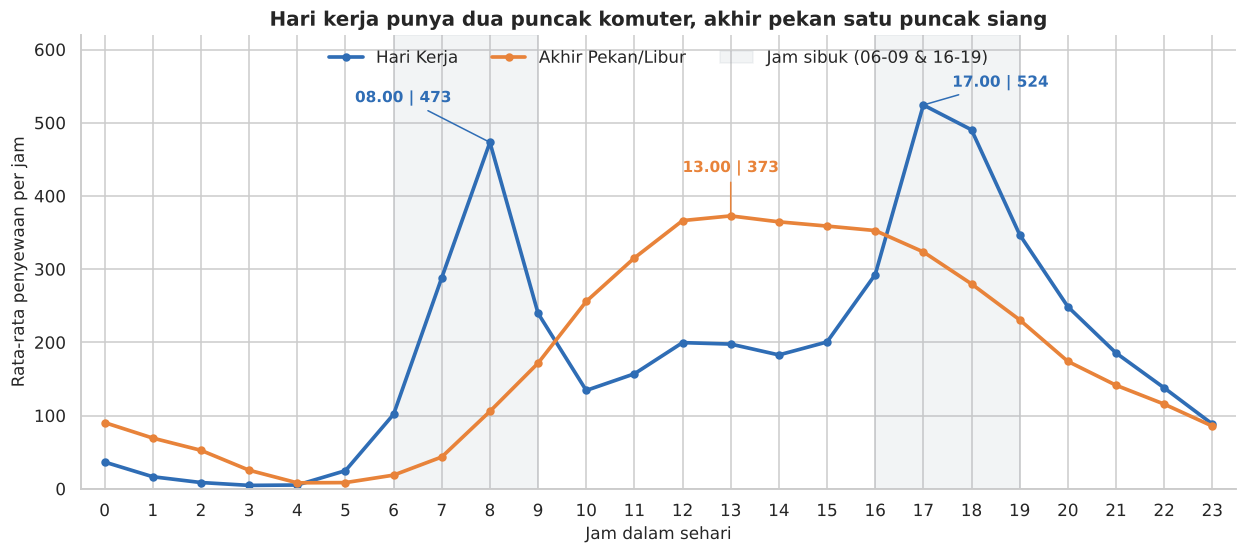

In [17]:
fig, ax = plt.subplots(figsize=(11.5, 5.2))

for dtype, color in [("Hari Kerja", BLUE), ("Akhir Pekan/Libur", ORANGE)]:
    s = hourly_pattern[dtype]
    ax.plot(s.index, s.values, marker="o", ms=4.5, lw=2.4, color=color, label=dtype)

# Area jam sibuk
ax.axvspan(6, 9, color=GREY, alpha=0.12)
ax.axvspan(16, 19, color=GREY, alpha=0.12, label="Jam sibuk (06-09 & 16-19)")

# Anotasi puncak
wk, we = hourly_pattern["Hari Kerja"], hourly_pattern["Akhir Pekan/Libur"]
peaks = [
    (wk[:12].idxmax(), wk[:12].max(), BLUE, (-1.8, 55)),
    (wk[12:].idxmax(), wk[12:].max(), BLUE, (1.6, 25)),
    (we.idxmax(), we.max(), ORANGE, (0, 60)),
]
for h, v, c, (dx, dy) in peaks:
    ax.annotate(f"{h:02d}.00 | {v:.0f}", xy=(h, v), xytext=(h + dx, v + dy), ha="center",
                fontsize=10, fontweight="bold", color=c,
                arrowprops=dict(arrowstyle="-", color=c, lw=1))

ax.set_xticks(range(24))
ax.set_xlim(-0.5, 23.5)
ax.set_ylim(0, 620)
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_title("Hari kerja punya dua puncak komuter, akhir pekan satu puncak siang")
ax.legend(frameon=False, loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Seberapa besar penurunan penyewaan harian saat cuaca tidak cerah, dan di musim apa dampaknya terbesar?

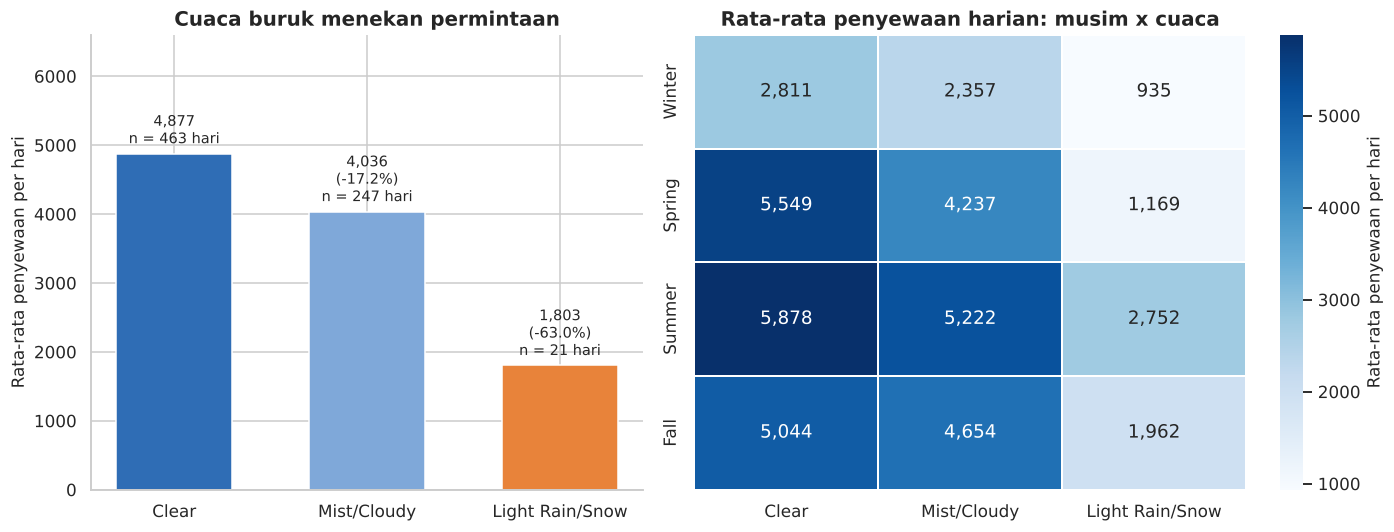

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})

# Panel kiri: rata-rata penyewaan harian per kondisi cuaca
ax = axes[0]
colors = [BLUE, "#7FA8D9", ORANGE]
bars = ax.bar(weather_stats.index, weather_stats["rata_rata"], color=colors, width=0.6)
for bar, (_, row) in zip(bars, weather_stats.iterrows()):
    label = f"{row['rata_rata']:,.0f}"
    if row["selisih_vs_cerah_%"] != 0:
        label += f"\n({row['selisih_vs_cerah_%']:+.1f}%)"
    label += f"\nn = {int(row['jumlah_hari'])} hari"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, label,
            ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, 6600)
ax.set_xlabel("")
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_title("Cuaca buruk menekan permintaan")

# Panel kanan: heatmap musim x cuaca
ax = axes[1]
sns.heatmap(season_weather, annot=True, fmt=",.0f", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Rata-rata penyewaan per hari"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Rata-rata penyewaan harian: musim x cuaca")
plt.tight_layout()
plt.show()

### Pertanyaan 3: Berapa pertumbuhan penyewaan 2012 vs 2011 dan segmen mana yang tumbuh lebih cepat?

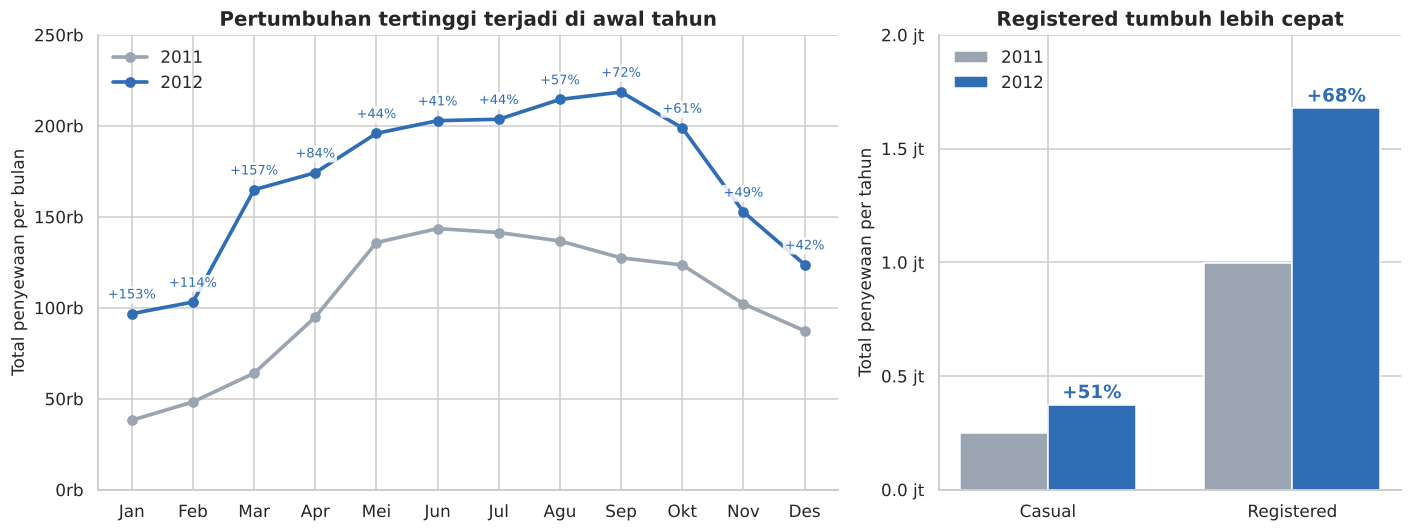

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})

# Panel kiri: total penyewaan bulanan 2011 vs 2012
ax = axes[0]
months = list(monthly.index)
ax.plot(months, monthly[2011], marker="o", lw=2.4, color=GREY, label="2011")
ax.plot(months, monthly[2012], marker="o", lw=2.4, color=BLUE, label="2012")
for m, v, g in zip(months, monthly[2012], monthly["pertumbuhan_yoy_%"]):
    ax.annotate(f"+{g:.0f}%", xy=(m, v), xytext=(0, 10), textcoords="offset points", ha="center",
                fontsize=8.5, color=BLUE, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1000:.0f}rb"))
ax.set_ylim(0, 250000)
ax.set_ylabel("Total penyewaan per bulan")
ax.set_title("Pertumbuhan tertinggi terjadi di awal tahun")
ax.legend(frameon=False, loc="upper left")

# Panel kanan: casual vs registered
ax = axes[1]
x = np.arange(2)
w = 0.36
b1 = ax.bar(x - w / 2, user_year.loc[2011, ["casual", "registered"]], w, color=GREY, label="2011")
b2 = ax.bar(x + w / 2, user_year.loc[2012, ["casual", "registered"]], w, color=BLUE, label="2012")
for i, seg in enumerate(["casual", "registered"]):
    ax.text(i + w / 2, user_year.loc[2012, seg] + 30000, f"+{growth_user[seg]:.0f}%",
            ha="center", fontweight="bold", color=BLUE)
ax.set_xticks(x)
ax.set_xticklabels(["Casual", "Registered"])
ax.set_yticks([0, 500000, 1000000, 1500000, 2000000])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:.1f} jt"))
ax.set_ylim(0, 2000000)
ax.set_ylabel("Total penyewaan per tahun")
ax.set_title("Registered tumbuh lebih cepat")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** Hari kerja memiliki puncak pukul 08.00 (sekitar 473 sewa/jam) dan 17.00 (sekitar 524 sewa/jam), sedangkan akhir pekan/libur memuncak pukul 13.00 (sekitar 373 sewa/jam). Jam sibuk (06-09 & 16-19) menyumbang sekitar 60% penyewaan hari kerja.
- **Pertanyaan 2:** Cuaca berkabut/berawan menurunkan penyewaan harian sekitar 17% dan hujan/salju ringan sekitar 63% dibanding cuaca cerah. Dampak terbesar ada pada musim Spring.
- **Pertanyaan 3:** Penyewaan 2012 tumbuh sekitar 65% dibanding 2011, dan pengguna registered tumbuh lebih cepat daripada casual.

## Analisis Lanjutan (Opsional)

Teknik **RFM** dan **geospatial** tidak relevan karena dataset ini tidak memiliki identitas pelanggan maupun koordinat lokasi. Teknik yang relevan dan digunakan (tanpa machine learning) adalah **Manual Grouping** dan **Binning**:

1. **Manual Grouping:** mengelompokkan 24 jam menjadi 5 segmen waktu berdasarkan aturan bisnis.
2. **Binning:** membagi suhu, kelembapan, dan kecepatan angin ke dalam interval untuk melihat rentang kondisi yang paling mendukung penyewaan.
3. **Binning tingkat permintaan harian:** mengelompokkan hari menjadi Rendah, Sedang, Tinggi, dan Sangat Tinggi, lalu melihat sebarannya per musim.

#### Manual grouping: segmen waktu dalam sehari

daytype,Akhir Pekan/Libur,Hari Kerja
segment,,
Dini hari (00-05),5.9,2.1
Rush pagi (06-09),7.8,24.1
Siang (10-15),47.0,23.4
Rush sore (16-19),27.4,36.1
Malam (20-23),11.9,14.4


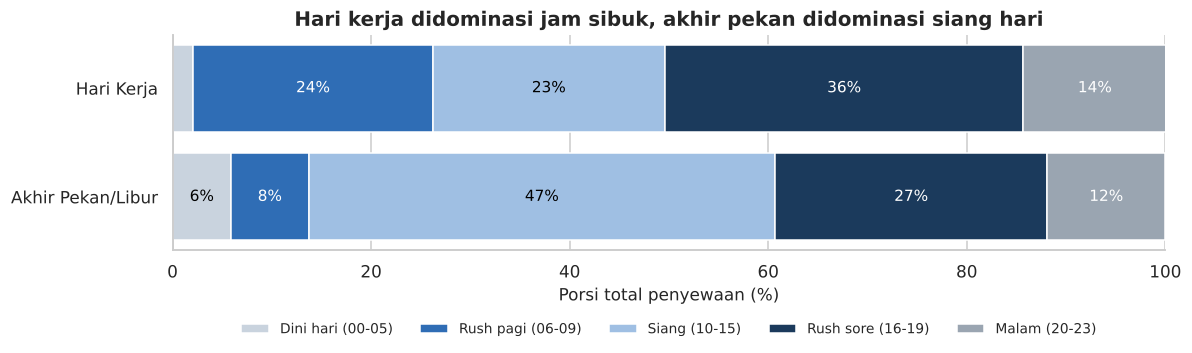

In [20]:
def time_segment(hr):
    if hr <= 5:
        return "Dini hari (00-05)"
    if hr <= 9:
        return "Rush pagi (06-09)"
    if hr <= 15:
        return "Siang (10-15)"
    if hr <= 19:
        return "Rush sore (16-19)"
    return "Malam (20-23)"

segment_order = ["Dini hari (00-05)", "Rush pagi (06-09)", "Siang (10-15)", "Rush sore (16-19)", "Malam (20-23)"]
hour_clean["segment"] = hour_clean["hr"].map(time_segment)

seg_total = hour_clean.pivot_table(index="segment", columns="daytype", values="cnt", aggfunc="sum").loc[segment_order]
seg_share = (seg_total / seg_total.sum() * 100).round(1)
display(seg_share)

seg_colors = ["#C9D3DE", BLUE, "#9FBFE3", DARK, GREY]
fig, ax = plt.subplots(figsize=(11, 3.6))
left = np.zeros(2)
dtypes = ["Hari Kerja", "Akhir Pekan/Libur"]
for seg, color in zip(segment_order, seg_colors):
    vals = seg_share.loc[seg, dtypes].values
    ax.barh(dtypes, vals, left=left, color=color, edgecolor="white", label=seg)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 4:  # segmen yang terlalu sempit tidak diberi label (nilainya ada pada tabel di atas)
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=10,
                    color="white" if color in (BLUE, DARK, GREY) else "black")
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("Porsi total penyewaan (%)")
ax.invert_yaxis()
ax.set_title("Hari kerja didominasi jam sibuk, akhir pekan didominasi siang hari")
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
plt.tight_layout()
plt.show()

#### Binning: suhu, kelembapan, dan kecepatan angin

Suhu


,rata_rata,jumlah_hari
temp_bin,,
< 10 C,1678.0,60
10-20 C,3692.0,299
20-30 C,5662.0,300
> 30 C,5410.0,72


Kelembapan


,rata_rata,jumlah_hari
hum_bin,,
< 40%,4478.0,28
40-60%,4575.0,293
60-80%,4759.0,318
> 80%,3404.0,92


Kecepatan angin


,rata_rata,jumlah_hari
wind_bin,,
< 10,4917.0,242
10-20,4464.0,418
> 20,3338.0,71


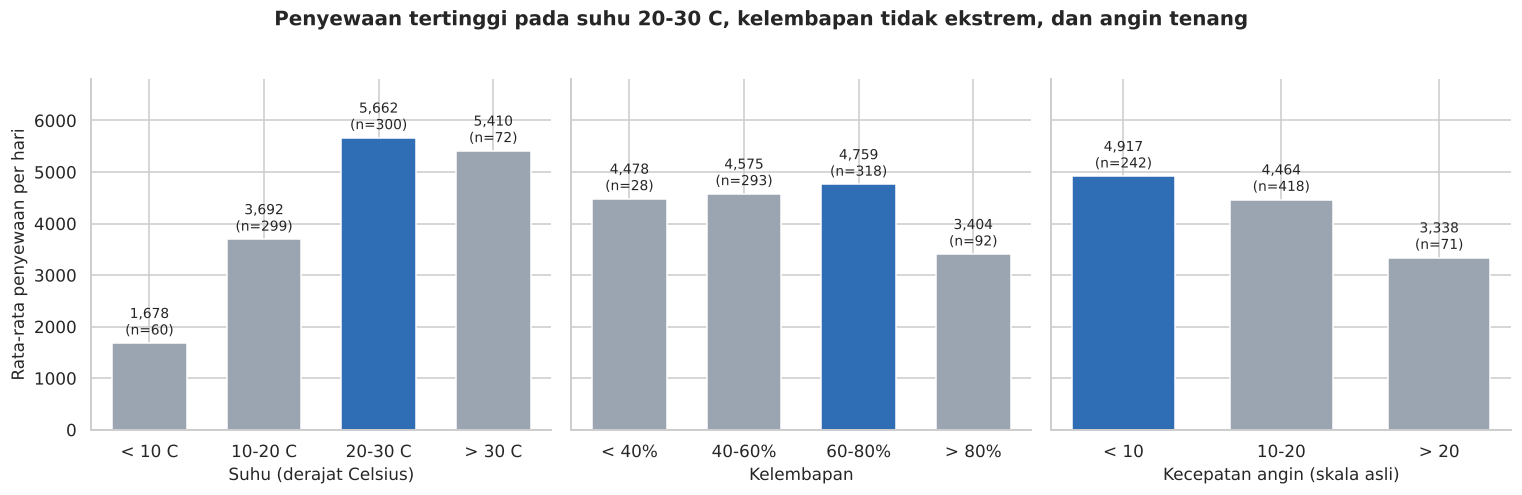

In [21]:
day_df["temp_bin"] = pd.cut(day_df["temp_c"], bins=[0, 10, 20, 30, 50],
                            labels=["< 10 C", "10-20 C", "20-30 C", "> 30 C"], right=False)
day_df["hum_bin"] = pd.cut(day_df["hum_pct"], bins=[0, 40, 60, 80, 101],
                           labels=["< 40%", "40-60%", "60-80%", "> 80%"], right=False)
day_df["wind_bin"] = pd.cut(day_df["wind"], bins=[0, 10, 20, 100],
                            labels=["< 10", "10-20", "> 20"], right=False)

bin_results = {}
for col, title in [("temp_bin", "Suhu"), ("hum_bin", "Kelembapan"), ("wind_bin", "Kecepatan angin")]:
    res = day_df.groupby(col, observed=True)["cnt"].agg(rata_rata="mean", jumlah_hari="count").round(0)
    bin_results[col] = res
    print(title)
    display(res)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
specs = [("temp_bin", "Suhu (derajat Celsius)"), ("hum_bin", "Kelembapan"), ("wind_bin", "Kecepatan angin (skala asli)")]
for ax, (col, title) in zip(axes, specs):
    res = bin_results[col]
    best = res["rata_rata"].idxmax()
    colors = [BLUE if idx == best else GREY for idx in res.index]
    bars = ax.bar(res.index.astype(str), res["rata_rata"], color=colors, width=0.65)
    for bar, n in zip(bars, res["jumlah_hari"]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80,
                f"{bar.get_height():,.0f}\n(n={int(n)})", ha="center", va="bottom", fontsize=9)
    ax.set_xlabel(title)
    ax.set_ylim(0, 6800)
axes[0].set_ylabel("Rata-rata penyewaan per hari")
fig.suptitle("Penyewaan tertinggi pada suhu 20-30 C, kelembapan tidak ekstrem, dan angin tenang",
             fontweight="bold", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

#### Binning: tingkat permintaan harian per musim

demand_level,Rendah (< 2.000),Sedang (2.000-3.999),Tinggi (4.000-5.999),Sangat tinggi (>= 6.000)
season_label,,,,
Winter,79,68,29,5
Spring,9,37,76,62
Summer,3,17,90,78
Fall,7,59,77,35


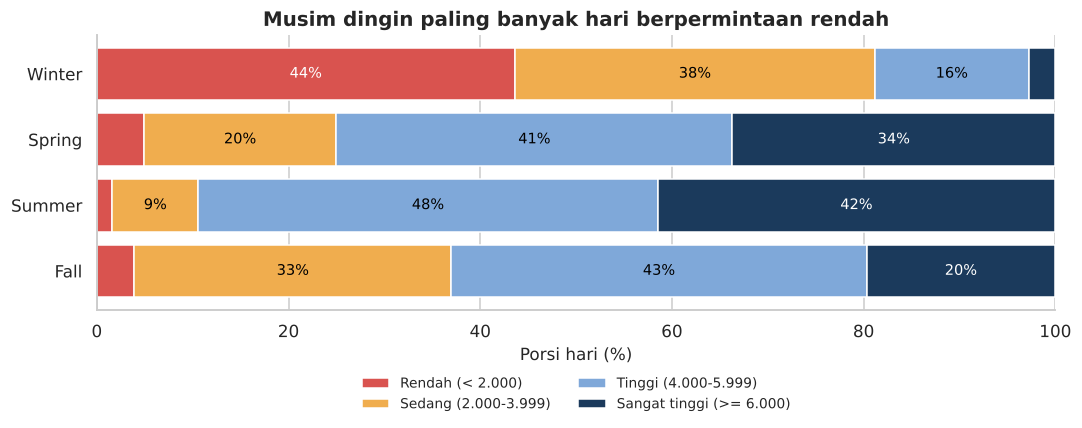

In [22]:
level_labels = ["Rendah (< 2.000)", "Sedang (2.000-3.999)", "Tinggi (4.000-5.999)", "Sangat tinggi (>= 6.000)"]
day_df["demand_level"] = pd.cut(day_df["cnt"], bins=[0, 2000, 4000, 6000, 10000], labels=level_labels, right=False)

level_season = pd.crosstab(day_df["season_label"], day_df["demand_level"]).loc[season_order]
level_share = (level_season.div(level_season.sum(axis=1), axis=0) * 100).round(1)
display(level_season)

lvl_colors = ["#D9534F", "#F0AD4E", "#7FA8D9", DARK]
fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(level_share))
for lvl, color in zip(level_labels, lvl_colors):
    vals = level_share[lvl].values
    ax.barh(level_share.index, vals, left=left, color=color, edgecolor="white", label=lvl)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9.5,
                    color="black" if color in ("#F0AD4E", "#7FA8D9") else "white")
    left += vals
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Porsi hari (%)")
ax.set_title("Musim dingin paling banyak hari berpermintaan rendah")
ax.legend(ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)
plt.tight_layout()
plt.show()

**Insight:**
- **Manual grouping:** pada hari kerja, rush pagi dan rush sore menyumbang sekitar 24% dan 36% penyewaan, sedangkan dini hari hanya sekitar 2%. Pada akhir pekan/libur, hampir separuh penyewaan (sekitar 47%) terjadi pada siang hari (10-15).
- **Binning:** rata-rata penyewaan harian paling tinggi pada suhu 20-30 derajat Celsius (sekitar 5.662), sedangkan pada suhu di bawah 10 derajat hanya sekitar 1.678. Permintaan juga turun saat kelembapan di atas 80% dan saat angin di atas 20 (skala asli).
- **Tingkat permintaan:** hampir semua hari berpermintaan rendah (<2.000 sewa) terjadi pada musim Winter (79 dari 98 hari), sementara musim Summer didominasi hari berpermintaan tinggi dan sangat tinggi.
- Pola ini bersifat asosiasi (korelasi suhu dengan penyewaan sekitar 0,63) dan tidak serta-merta berarti sebab-akibat.

#### Menyimpan data bersih untuk dashboard

In [23]:
out_dir = Path("dashboard")
out_dir.mkdir(exist_ok=True)

hour_cols = ["dteday", "hr", "season_label", "year", "mnth", "month_name", "weekday_name", "workingday",
             "daytype", "segment", "weather", "temp_c", "hum_pct", "wind", "casual", "registered", "cnt", "is_filled"]
day_cols = ["dteday", "season_label", "year", "mnth", "month_name", "weekday_name", "workingday", "daytype",
            "weather", "temp_c", "hum_pct", "wind", "temp_bin", "hum_bin", "wind_bin", "demand_level",
            "casual", "registered", "cnt"]

hour_clean[hour_cols].to_csv(out_dir / "main_data.csv", index=False)
day_df[day_cols].to_csv(out_dir / "day_data.csv", index=False)
print("Tersimpan:", [p.name for p in out_dir.glob("*.csv")])

Tersimpan: ['main_data.csv', 'day_data.csv']


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Permintaan pada **hari kerja** memuncak dua kali: pukul 08.00 (sekitar 473 sewa/jam) dan terutama pukul 17.00 (sekitar 524 sewa/jam), dan jam sibuk (06-09 & 16-19) menyumbang sekitar **60%** penyewaan hari kerja. Pada **akhir pekan/libur**, permintaan memuncak pukul 13.00 (sekitar 373 sewa/jam) dengan sekitar 47% penyewaan terjadi pukul 10-15. Dini hari (00-05) hanya menyumbang sekitar 2% penyewaan hari kerja.
- **Conclusion pertanyaan 2:** Dibanding cuaca cerah (rata-rata sekitar 4.877 sewa/hari), penyewaan turun sekitar **17%** saat berkabut/berawan dan sekitar **63%** saat hujan/salju ringan. Dampak relatif terbesar terjadi pada musim **Spring** (turun sekitar 24% dan 79%), sedangkan musim Winter memiliki tingkat dasar permintaan paling rendah (sekitar 2.811 sewa/hari saat cerah). Catatan: sampel hari hujan/salju ringan kecil (21 hari).
- **Conclusion pertanyaan 3:** Total penyewaan 2012 tumbuh sekitar **64,9%** dibanding 2011 (1,24 juta menjadi 2,05 juta). Pertumbuhan terbesar terjadi pada awal tahun (Januari sekitar +153%, Maret sekitar +157%) dan melambat menjadi sekitar +41% sampai +44% pada pertengahan dan akhir tahun, sebagian karena basis 2011 yang masih rendah. Pengguna **registered** tumbuh lebih cepat (sekitar +68%) dibanding **casual** (sekitar +51%).

**Rekomendasi Action Item:**
- **Redistribusi armada berbasis jam:** pada hari kerja, pastikan stok sepeda dan dok di area komuter terisi sebelum pukul 07.00 dan pukul 16.00. Lakukan redistribusi dan perawatan rutin pada dini hari (00-05) saat permintaan hanya sekitar 2% dari total hari kerja.
- **Pisahkan penjadwalan akhir pekan:** geser fokus armada ke area rekreasi/wisata pada pukul 10-15 di akhir pekan dan hari libur, serta jalankan promo untuk pengguna casual pada jam tersebut.
- **Mitigasi cuaca:** gunakan prakiraan cuaca untuk menyesuaikan jumlah sepeda yang disebar dan menjadwalkan perawatan pada hari yang diprediksi hujan, karena permintaan bisa turun hingga sekitar 63%. Pertimbangkan promo atau fitur keselamatan pada cuaca berkabut/berawan, dan perhatikan khususnya musim Spring yang dampaknya paling besar.
- **Prioritaskan segmen registered, dorong konversi casual:** karena registered tumbuh lebih cepat dan sudah menyumbang sekitar 82% penyewaan, fokuskan retensi dan program komuter pada segmen ini, sambil menyiapkan penawaran konversi (promo langganan) untuk pengguna casual yang aktif di akhir pekan.
- **Langkah lanjutan:** tambahkan data lokasi stasiun (jika tersedia) agar redistribusi bisa dianalisis per wilayah, dan evaluasi pertumbuhan dengan data tahun berikutnya untuk memisahkan efek musiman dari tren jangka panjang.